### Feature selection algorithms comparison
Comparing different supervised feature selection methods for classification problems, using conventional flat features.

# Collect- and mine data

In [1]:
import pandas as pd
from tqdm import tqdm
datacol = pd.read_csv('./data/benchmark_24-replicas.csv')
result_dirs = ['../../results/11714894_subsets', '../../results/11824789']
chunks = []
for _, dataset in tqdm(datacol.iterrows(), total=len(datacol)):
    for result_dir in result_dirs:
        respath = os.path.join(result_dir, 'stats', dataset.path + '.csv')
        if os.path.exists(respath):
            chunks.append(pd.read_csv(respath))
statdata = pd.concat(chunks)
del chunks
# statdata.to_csv('./data/statdata.csv', index=False)
print('statdata successfully collected.')

100%|██████████| 1828/1828 [00:16<00:00, 110.46it/s]
statdata successfully collected.


In [2]:
# statdata = pd.read_csv('./data/statdata.csv')
statdata = statdata[statdata['ranking_method'] != 'Stability Selection']
print(statdata.shape)
statdata.head()

(751260, 11)


,cpu_time,feature_rank,ranking_method,replica_no,name,description,recall,precision,fpr,f1,auc
0,3.855204,4.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.333333,0.222222,0.500000,NaN
1,3.855204,11.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.100000,1.000000,0.181818,NaN
2,3.855204,5.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.250000,0.333333,0.400000,NaN
3,3.855204,3.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.500000,0.111111,0.666667,NaN
4,3.855204,11.0,RFE w/XGBoost,1,Continuous Features,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",1.0,0.100000,1.000000,0.181818,NaN


PR and ROC Curve

100%|██████████| 141/141 [00:01<00:00, 78.39it/s]


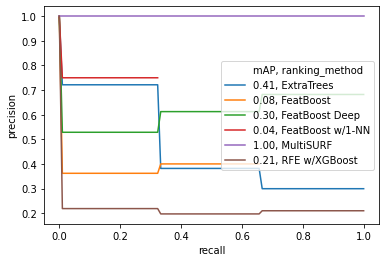

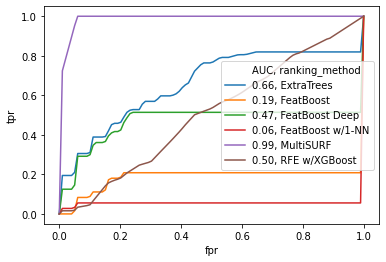

In [365]:
tqdm.pandas()

interpdataaa = statdata[statdata['name']==exname]\
    .groupby(['description', 'ranking_method', 'replica_no'])\
    .progress_apply(compute_interpolated_metrics)\
    .reset_index()
interpdataaa2 = interpdataaa\
    .groupby(['description', 'ranking_method' ])\
    .agg({ 'AP': 'mean', 'auc': 'mean' })\
    .rename(columns={ 'AP': 'mAP', 'auc': 'AUC' })\
    .reset_index()
interpdataaa3 = interpdataaa.merge(interpdataaa2)
add_metric_to_legend = lambda entry, metric: '{:.2f}, {}'.format(metric, entry)
interpdataaa3['mAP, ranking_method'] = interpdataaa3['ranking_method']\
    .combine(interpdataaa3['mAP'], add_metric_to_legend)
interpdataaa3['AUC, ranking_method'] = interpdataaa3['ranking_method']\
    .combine(interpdataaa3['AUC'], add_metric_to_legend)
sns.lineplot(data=interpdataaa3, x='recall', y='precision', hue='mAP, ranking_method',
    err_style=None)
plt.show()
sns.lineplot(data=interpdataaa3, x='fpr', y='tpr', hue='AUC, ranking_method',
    err_style=None)
plt.show()

In [364]:
def compute_roc_curve(replica):
    return pd.DataFrame({ 'fpr': interp_fpr, 'tpr': interp_tpr, 'auc': auc })

def compute_interpolated_metrics(replica):
    # ROC
    interp_fpr = np.linspace(0, 1, 100)
    fprs = replica.sort_values('fpr').fpr.values
    tprs = replica.sort_values('fpr').recall.values
    interp_tpr = np.interp(interp_fpr, fprs, tprs)
    interp_tpr[0] = 0.0
    interp_tpr[-1] = 1.0
    auc = np.trapz(interp_tpr, interp_fpr)

    # PR curve
    precision, recall, AP = interpolate_pr(replica)
    precision_, recall_, _ = sample_interp_pr(precision, recall)
    return pd.DataFrame({ 'fpr': interp_fpr, 'tpr': interp_tpr, 'auc': auc,
                          'precision': precision_, 'recall': recall_, 'AP': AP })


auc
description                                        ranking_method            
3-way Epistasis (GAMETES) [p=20,n=1600,p_=3,h=0... ExtraTrees        0.656090
                                                   FeatBoost         0.188427
                                                   FeatBoost Deep    0.469392
                                                   FeatBoost w/1-NN  0.058696
                                                   MultiSURF         0.986787
                                                   RFE w/XGBoost     0.504838

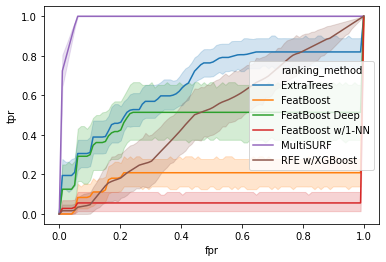

In [362]:
interpdataaa = statdata[statdata['name']==exname]\
    .groupby(['description', 'ranking_method', 'replica_no'])\
    .apply(compute_roc_curve)\
    .reset_index()
sns.lineplot(data=interpdataaa, x='fpr', y='tpr', hue='ranking_method')
interpdataaa\
    .groupby(['description', 'ranking_method'])\
    .agg({'auc': 'mean'})\
    .rename

# interpdataaa2 = interpdataaa\
#     .groupby(['description', 'ranking_method' ])\
#     .agg({ 'AP': 'mean' })\
#     .rename(columns={ 'AP': 'mAP' })\
#     .reset_index()


In [338]:
from tqdm import tqdm
import numpy as np
from scipy import interpolate

# compute means over several replicas by interpolation
# https://scikit-learn.org/stable/auto_examples/model_selection/plot_roc_crossval.html#sphx-glr-download-auto-examples-model-selection-plot-roc-crossval-py
def interpolate_mean_roc(replicas):
    ys = []
    mean_x = np.linspace(0, 1, 100)
    for key, data in replicas.groupby([ 'replica_no' ]):
        x = data.sort_values('fpr').fpr.values
        y = data.sort_values('fpr').recall.values
        interp_y = np.interp(mean_x, x, y)
        interp_y[0] = 0.0
        ys.append(interp_y)
    mean_y = np.mean(ys, axis=0)
    mean_y[-1] = 1.0
    auc = np.trapz(mean_y, mean_x)
    return mean_x, mean_y, auc

# https://towardsdatascience.com/breaking-down-mean-average-precision-map-ae462f623a52
def interpolate_pr(replica):
    recalls = np.unique(replica.recall)
    def max_precision(recall): # find max precision value given recall
        return replica[replica['recall'] == recall]['precision'].max()
    precisions = list(map(max_precision, recalls))
    precision, recall = np.r_[1, precisions], np.r_[0, recalls]
    AP = np.sum(np.r_[0, np.diff(recall)] * precision)
    return precision, recall, AP

# interpolate PR curve over some recall points to obtain graphical curve representation
def sample_interp_pr(precision, recall):
    fn = interpolate.interp1d(recall, precision, kind='next',\
                              bounds_error=False) # fill out of bounds with NaN's
                              # fill_value='extrapolate')
                              # extrapolating would mean finishing
                              # any curve by filling the last values
                              # when curve stops before recall == 1.0
    recalls = np.linspace(0, 1, 100)
    precisions = fn(recalls)

    # compute AP. exclude NaN's by interpolating only over real recall values.
    real_recalls = np.linspace(0, recall.max(), 100)
    real_precisions = fn(real_recalls)
    AP = np.trapz(real_precisions, real_recalls) # interpolated AP
    
    return precisions, recalls, AP

def compute_pr_curve(replica):
    precision, recall, AP = interpolate_pr(replica)
    precision_, recall_, _ = sample_interp_pr(precision, recall)
    return pd.DataFrame({ 'precision': precision_, 'recall': recall_, 'AP': AP })

def interpolate_mean_ap(replicas):
    mP = []  # mean precisions
    mR = []  # mean recall
    mAP = [] # mean AP
    for _, replica in replicas.groupby('replica_no'):
        precision, recall, AP = interpolate_pr(replica)
        precision_, recall_, _ = sample_interp_pr(precision, recall)
        mP.append(precision_)
        mR.append(recall_)
        mAP.append(AP)
    return np.nanmean(mP, axis=0), np.mean(mR, axis=0), np.mean(mAP)

interpdata = []
for key, replicas in tqdm(statdata.groupby([ 'description', 'ranking_method' ])):
    description, ranking_method = key
    name = replicas['name'].values[0]
    fpr, tpr, roc_auc = interpolate_mean_roc(replicas)
    precision, recall, mAP = interpolate_mean_ap(replicas)
    
    interpdata.append(pd.DataFrame(data={
        'description': description,
        'multiline_description': description.replace(' [p=', '\n[p='),
        'name': name,
        'ranking_method': ranking_method,
        'fpr': fpr,
        'tpr': tpr,
        'roc_auc': roc_auc,
        'precision': precision,
        'recall': recall,
        'mAP': mAP
    }))
interpdata = pd.concat(interpdata)
interpdata.shape

In [4]:
interpdata

,description,multiline_description,name,ranking_method,fpr,tpr,roc_auc,precision,recall,mAP
0,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]","1 Main Effect\n[p=20,n=1600,p_=1,h=0.05,edm=Easy]",1 Main Effect,ExtraTrees,0.000000,0.000000,0.965875,1.000000,0.000000,0.855556
1,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]","1 Main Effect\n[p=20,n=1600,p_=1,h=0.05,edm=Easy]",1 Main Effect,ExtraTrees,0.010101,0.791667,0.965875,0.855556,0.010101,0.855556
2,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]","1 Main Effect\n[p=20,n=1600,p_=1,h=0.05,edm=Easy]",1 Main Effect,ExtraTrees,0.020202,0.791667,0.965875,0.855556,0.020202,0.855556
3,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]","1 Main Effect\n[p=20,n=1600,p_=1,h=0.05,edm=Easy]",1 Main Effect,ExtraTrees,0.030303,0.791667,0.965875,0.855556,0.030303,0.855556
4,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]","1 Main Effect\n[p=20,n=1600,p_=1,h=0.05,edm=Easy]",1 Main Effect,ExtraTrees,0.040404,0.791667,0.965875,0.855556,0.040404,0.855556
...,...,...,...,...,...,...,...,...,...,...
95,"XOR Models [p=20,n=1600,p_=5,h=1]","XOR Models\n[p=20,n=1600,p_=5,h=1]",XOR Models,RFE w/XGBoost,0.959596,0.989226,0.712758,0.363509,0.959596,0.454940
96,"XOR Models [p=20,n=1600,p_=5,h=1]","XOR Models\n[p=20,n=1600,p_=5,h=1]",XOR Models,RFE w/XGBoost,0.969697,0.991919,0.712758,0.363509,0.969697,0.454940
97,"XOR Models [p=20,n=1600,p_=5,h=1]","XOR Models\n[p=20,n=1600,p_=5,h=1]",XOR Models,RFE w/XGBoost,0.979798,0.994613,0.712758,0.363509,0.979798,0.454940
98,"XOR Models [p=20,n=1600,p_=5,h=1]","XOR Models\n[p=20,n=1600,p_=5,h=1]",XOR Models,RFE w/XGBoost,0.989899,0.997306,0.712758,0.363509,0.989899,0.454940


Compute replica counts per recall point for PR curves.

In [310]:
tqdm.pandas()
# Compute Precision/Recall
def attach_pr_info(replica):
    precision, recall, AP = interpolate_pr(replica)
    precision_, recall_, _ = sample_interp_pr(precision, recall)
    return pd.DataFrame({ 'precision': precision_, 'recall': recall_, 'AP': AP })
prdata_ = statdata\
    .groupby(['description', 'ranking_method', 'replica_no'])\
    .progress_apply(attach_pr_info)\
    .reset_index()

# Compute replica count per plateau
def get_counts(data):
    return pd.Series({'counts': data['precision'].count()})
def add_count(data, all_plateaus=None):
    count = data['precision'].count()
    idx = np.argwhere(all_plateaus == count)[0][0]
    plateaus = all_plateaus[idx:]
    return pd.Series({
        'replica count': plateaus,            # vector
        'precision': data['precision'].mean() # scalar
    })
def set_count(group):
    counts = group.groupby('recall').apply(get_counts).reset_index()
    plateaus = np.r_[0, np.where(np.diff(counts['counts'].values))[0] + 1]
    plateaucounts = counts['counts'].values[plateaus]
    assert(~(np.diff(plateaucounts) >= 0).any()) # ensure descending order
    return group.groupby('recall').apply(add_count, all_plateaus=plateaucounts)
prdata = prdata_\
    .groupby(['description', 'ranking_method'])\
    .progress_apply(set_count)\
    .explode('replica count')\
    .astype({'replica count': int })\
    .reset_index()
prdata.shape

100%|██████████| 418/418 [01:47<00:00,  3.89it/s]


(50277, 5)

In [315]:
prdata

,description,ranking_method,recall,replica count,precision
0,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",ExtraTrees,0.000000,24,1.000000
1,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",ExtraTrees,0.010101,24,0.855556
2,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",ExtraTrees,0.020202,24,0.855556
3,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",ExtraTrees,0.030303,24,0.855556
4,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",ExtraTrees,0.040404,24,0.855556
...,...,...,...,...,...
50272,"XOR Models [p=20,n=1600,p_=5,h=1]",RFE w/XGBoost,0.959596,24,0.363509
50273,"XOR Models [p=20,n=1600,p_=5,h=1]",RFE w/XGBoost,0.969697,24,0.363509
50274,"XOR Models [p=20,n=1600,p_=5,h=1]",RFE w/XGBoost,0.979798,24,0.363509
50275,"XOR Models [p=20,n=1600,p_=5,h=1]",RFE w/XGBoost,0.989899,24,0.363509


# 3-way Epistasis example

In [5]:
exname = '3-way Epistasis (GAMETES)'
exdata = interpdata[interpdata['name'] == exname]
exdata['description'].values[0]

'3-way Epistasis (GAMETES) [p=20,n=1600,p_=3,h=0.4,edm=Easy]'

Raw ranking data in table format

In [7]:
# informative features for this dataset are: `p_informative=[17, 18, 19]`
exdata_replica1 = pd.read_csv('../../results/11714894_subsets/ranking/data/rebate/GAMETES_2.2_dev_peter_epi_order_Datasets_Loc_3_Qnt_2_Pop_100000/a_20/s_1600/her_0.2__maf_0.2/a_20s_1600her_0.2__maf_0.2_EDM-2/a_20s_1600her_0.2__maf_0.2_EDM-2_01.txt.gz.csv')
exdata_replica1_ = exdata_replica1[exdata_replica1['ranking_method'] == 'ExtraTrees']\
    .sort_values('feature_rank')
exdata_replica1_['informative'] = exdata_replica1_['feature_index'].isin([17, 18, 19])
exdata_replica1_['informative'] = exdata_replica1_['informative'].map(lambda bool: 'Y' if bool else 'N')
exdata_replica1_['feature_rank'] = exdata_replica1_['feature_rank'].astype(int)
exdata_replica1_['feature_index'] = exdata_replica1_['feature_index'].astype(int)
exdata_replica1_t = exdata_replica1_[['feature_rank', 'feature_index', 'informative']].transpose()
exdata_replica1_t # can be copied into https://www.tablesgenerator.com/latex_tables

,64,61,60,51,62,59,53,55,58,63,54,56,57,52
feature_rank,1,2,3,4,5,6,7,8,9,10,11,12,13,14
feature_index,19,16,15,2,17,14,6,8,12,18,7,10,11,3
informative,Y,N,N,N,Y,N,N,N,N,Y,N,N,N,N


## Plots for just ExtraTrees

In [89]:
et_rm = 'ExtraTrees'
et = statdata[(statdata['name'] == exname) &\
              (statdata['ranking_method'] == et_rm)]
et = et.sort_values('feature_rank')
et.shape

(285, 11)

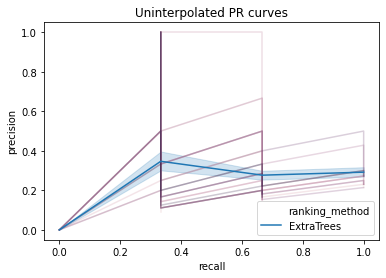

In [90]:
g = sns.lineplot(data=et, x='recall', y='precision', hue='replica_no',\
                 estimator=None, units='replica_no',
                 legend=False, sort=False, alpha=0.25)
g = sns.lineplot(data=et, x='recall', y='precision', hue='ranking_method')
plt.title('Uninterpolated PR curves')
plt.show()

In [91]:
mAP = []
mP = [] # mean precisions
mR = [] 
for _, replica in et.groupby('replica_no'):
    precision, recall, AP = interpolate_pr(replica)
    precision_, recall_, _ = sample_interp_pr(precision, recall)
    mAP.append(AP)
    mP.append(precision_)
    mR.append(recall_)
m_AP = np.mean(mAP)
m_P = np.nanmean(mP, axis=0)
m_R = np.mean(mR, axis=0)

counts = np.count_nonzero(~np.isnan(mP), axis=0)
norm_counts = counts / counts.max() / 5
diff_counts = np.where(np.r_[0, np.diff(m_P)])[0]
labels_recall = np.array(m_R)[[diff_counts]]
labels_count = counts[diff_counts]
labels_y = m_P[diff_counts + 1]
all_counts = [norm_counts for _ in range(len(mP))]

data = pd.DataFrame({
    'precision': pd.Series(mP).explode().astype(float),
    'recall': pd.Series(mR).explode().astype(float),
    'replicas': pd.Series(all_counts).explode().astype(float),
    'ranking_method': et_rm
})
data['replica'] = data.index
# sns.lineplot(x=m_R, y=m_P)
# plt.ylim(0, 1)
# np.trapz(m_P, m_R)
list(zip(labels_recall, labels_y, labels_count))

[(0.010101010101010105, 0.7215277777777778, 24),
 (0.3333333333333332, 0.381711525189786, 23),
 (0.6666666666666664, 0.29931734931734927, 12)]

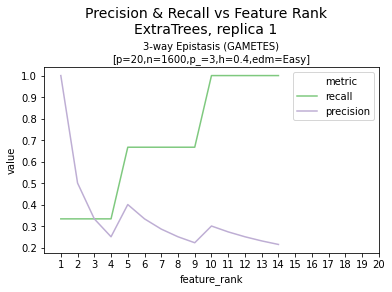

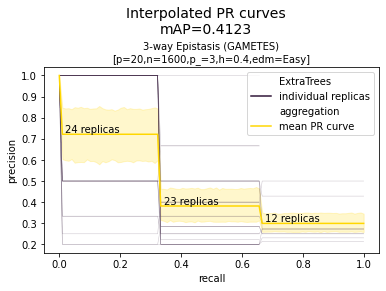

In [92]:
##### Uninterpolated PR curve replica 1
repl1 = et[et['replica_no'] == 1]
repl1_ = repl1.melt(id_vars=['feature_rank'], value_vars=['recall', 'precision'],\
                   var_name='metric')
plt.xticks(np.arange(1, 20+1, 1.0))
plt.xlim(right=20)
sns.lineplot(data=repl1_,
             x='feature_rank',
             y='value',
             hue='metric',
             palette="Accent")
plt.suptitle('Precision & Recall vs Feature Rank\n{}, replica 1'\
    .format(et_rm), size=14)
plt.subplots_adjust(top=.77)
plt.title("3-way Epistasis (GAMETES)\n[p=20,n=1600,p_=3,h=0.4,edm=Easy]", size=10)
plt.savefig('/Users/dunnkers/git/research-internship-report/img/3way_repl1pr.svg')
plt.show()

##### Interpolated PR curves (mAP)
data1 = data.copy()
data1[et_rm] = 'individual replicas'
sns.lineplot(data=data1, x='recall', y='precision', estimator=None, units='replica',
    lw=0.5, alpha=0.25, hue=et_rm, palette='twilight')
data2 = data.copy()
data2['aggregation'] = 'mean PR curve'
sns.lineplot(data=data2, x='recall', y='precision', hue='aggregation', palette='prism')
for point in zip(labels_recall, labels_count, labels_y):
    recall, count, y = point
    plt.text(recall + 0.01, y + 0.01, '{} replicas'.format(count))
plt.suptitle('Interpolated PR curves\nmAP={:.4f}'.format(m_AP), size=14)
plt.subplots_adjust(top=.77)
plt.title("3-way Epistasis (GAMETES)\n[p=20,n=1600,p_=3,h=0.4,edm=Easy]", size=10)
plt.savefig('/Users/dunnkers/git/research-internship-report/img/3way_etpr.svg')
plt.show()

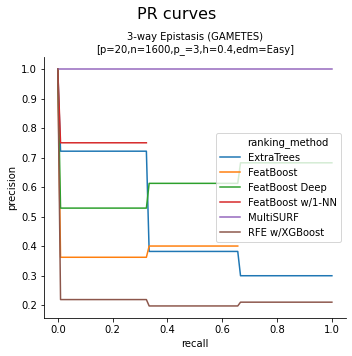

In [313]:
import seaborn as sns
import matplotlib.pyplot as plt
g = sns.relplot(data=exdata,\
                x='recall', y='precision', hue='ranking_method',\
                col='multiline_description', kind='line',\
                estimator=None, col_wrap=1,\
                facet_kws={'sharex': False, 'sharey': False,\
                           'legend_out': False}
                )
g.set_titles("{col_name}")
g.fig.suptitle("PR curves", size=16)
g.fig.subplots_adjust(top=.84)
plt.savefig('/Users/dunnkers/git/research-internship-report/img/3way_pr.svg')
plt.show()

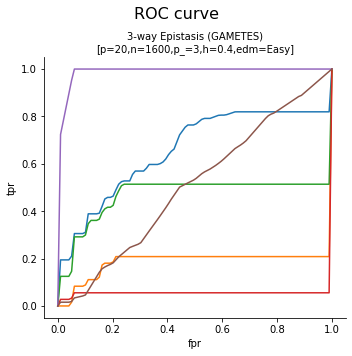

In [312]:
import seaborn as sns
import matplotlib.pyplot as plt
g = sns.relplot(data=exdata,\
                x='fpr', y='tpr', hue='ranking_method',\
                col='multiline_description', kind='line',\
                estimator=None, col_wrap=1,\
                facet_kws={'sharex': False, 'sharey': False},
                legend=False)
g.set_titles("{col_name}")
g.fig.suptitle("ROC curve", size=16)
g.fig.subplots_adjust(top=.84)
plt.savefig('/Users/dunnkers/git/research-internship-report/img/3way_roc.svg')
plt.show()

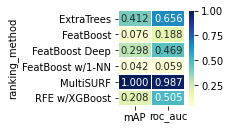

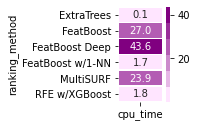

In [30]:
rectangular = pd.pivot_table(exdata,\
    values=['roc_auc', 'mAP'],\
    # index=['cpu_time'],\
    index=['ranking_method'])
f, ax = plt.subplots(figsize=(1.5, 1.75))
plt.yticks(rotation=0)
plt.xticks(rotation=0)
g = sns.heatmap(rectangular,\
    annot=True, fmt=".3f", linewidths=.5,\
    cmap="YlGnBu", yticklabels=True, ax=ax)
plt.savefig('/Users/dunnkers/git/research-internship-report/img/3way_AUC_mAP.svg')
plt.show()

rectangular = pd.pivot_table(statdata[statdata['name'] == exname],\
    values=['cpu_time'],\
    # index=['cpu_time'],\
    index=['ranking_method'])
f, ax = plt.subplots(figsize=(1, 1.75))
plt.yticks(rotation=0)
plt.xticks(rotation=0)
g = sns.heatmap(rectangular,\
    annot=True, fmt=".1f", linewidths=.5,\
    cmap=sns.light_palette('purple'), yticklabels=True, ax=ax)

    .groupby(['description', 'ranking_method', 'replica_no'])\
    .apply(compute_roc_curve)\
    .reset_index()
sns.lineplot(data=interpdataaa, x='fpr', y='tpr', hue='ranking_method')

# Dataset themes
_en masse_

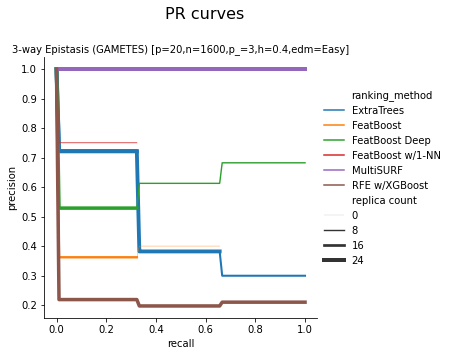

In [307]:
g = sns.relplot(data=res_[
        res_['description'] == '3-way Epistasis (GAMETES) [p=20,n=1600,p_=3,h=0.4,edm=Easy]'
    ],
    x='recall', y='precision', hue='ranking_method',
    col_wrap=1, kind='line', col='description', 
    size='replica count', sizes=(.10, 4.0),
    facet_kws={'legend_out': True}
)
g.set_titles("{col_name}")
g.fig.suptitle("PR curves", size=16)
g.fig.subplots_adjust(top=.84)

# All datasets

mAP scores

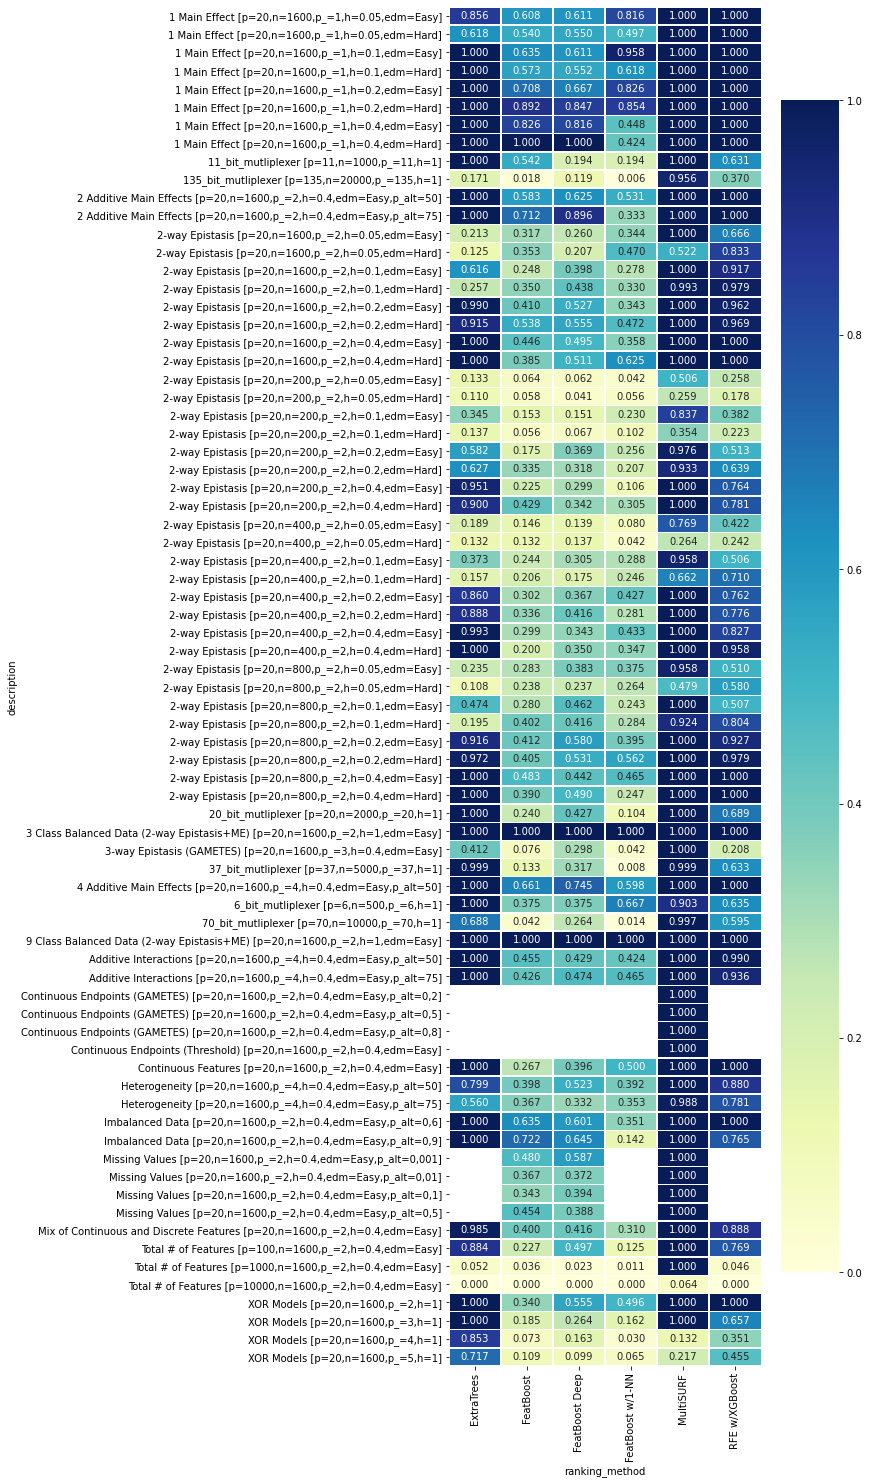

In [141]:
rectangular = pd.pivot_table(interpdata,\
    values='mAP',\
    index=['description'],\
    columns=['ranking_method'])
f, ax = plt.subplots(figsize=(7, 25))
plt.yticks(rotation=0)
plt.xticks(rotation=0)
g = sns.heatmap(rectangular,\
    annot=True, fmt=".3f", linewidths=.5,\
    cmap="YlGnBu", yticklabels=True, ax=ax)

AUC scores

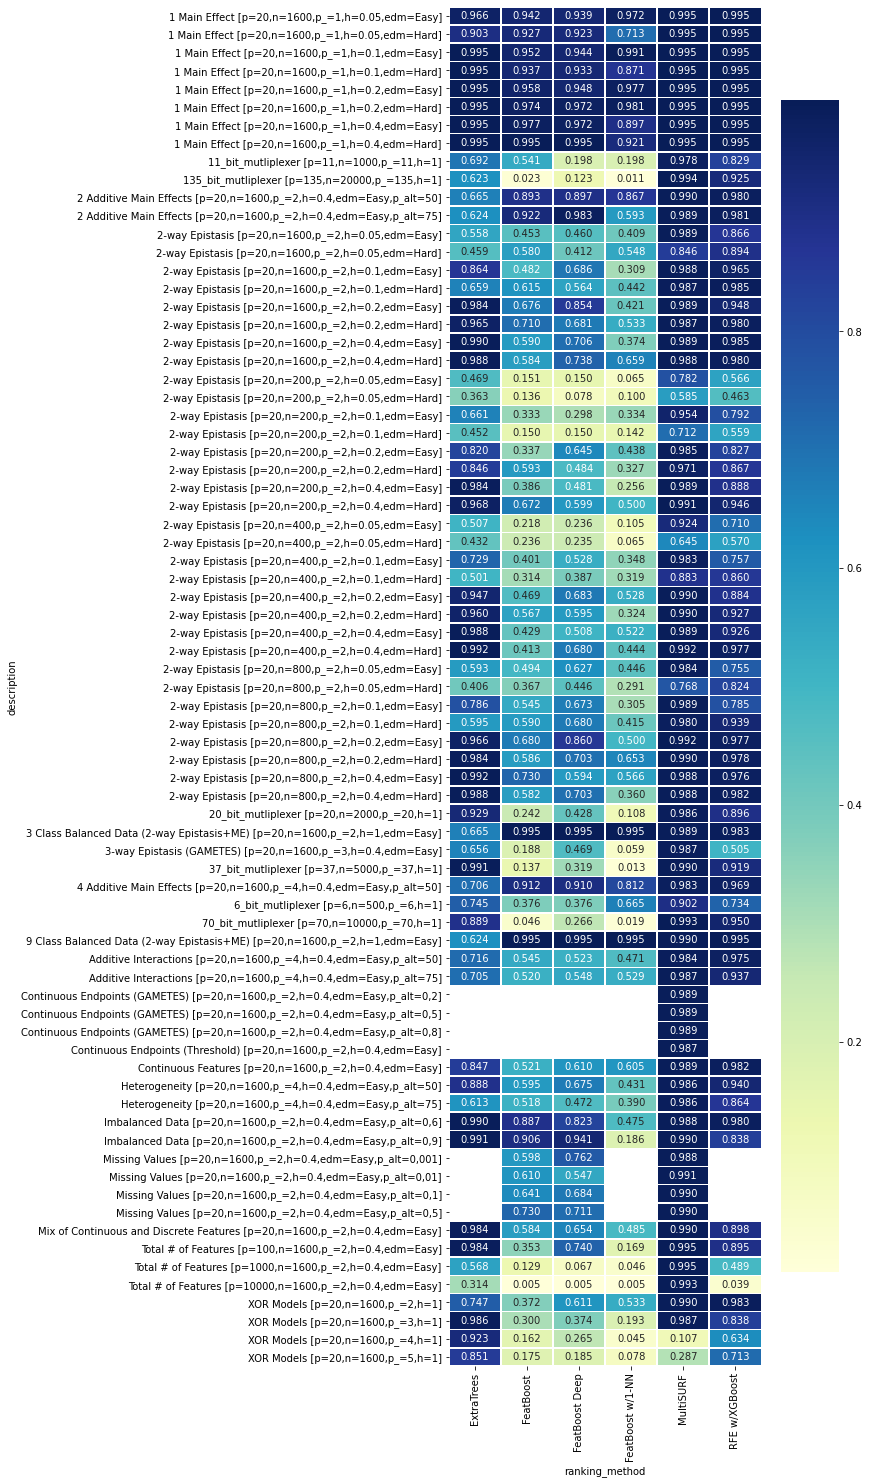

In [103]:
roc_auc_pivot = pd.pivot_table(interpdata,\
    values='roc_auc',\
    index=['description'],\
    columns=['ranking_method'])
f, ax = plt.subplots(figsize=(7, 25))
plt.yticks(rotation=0)
plt.xticks(rotation=0)
g = sns.heatmap(roc_auc_pivot,\
    annot=True, fmt=".3f", linewidths=.5,\
    cmap="YlGnBu", yticklabels=True, ax=ax)

CPU timings

Text(0.5, 1.0, 'cpu time per ranking method in seconds')

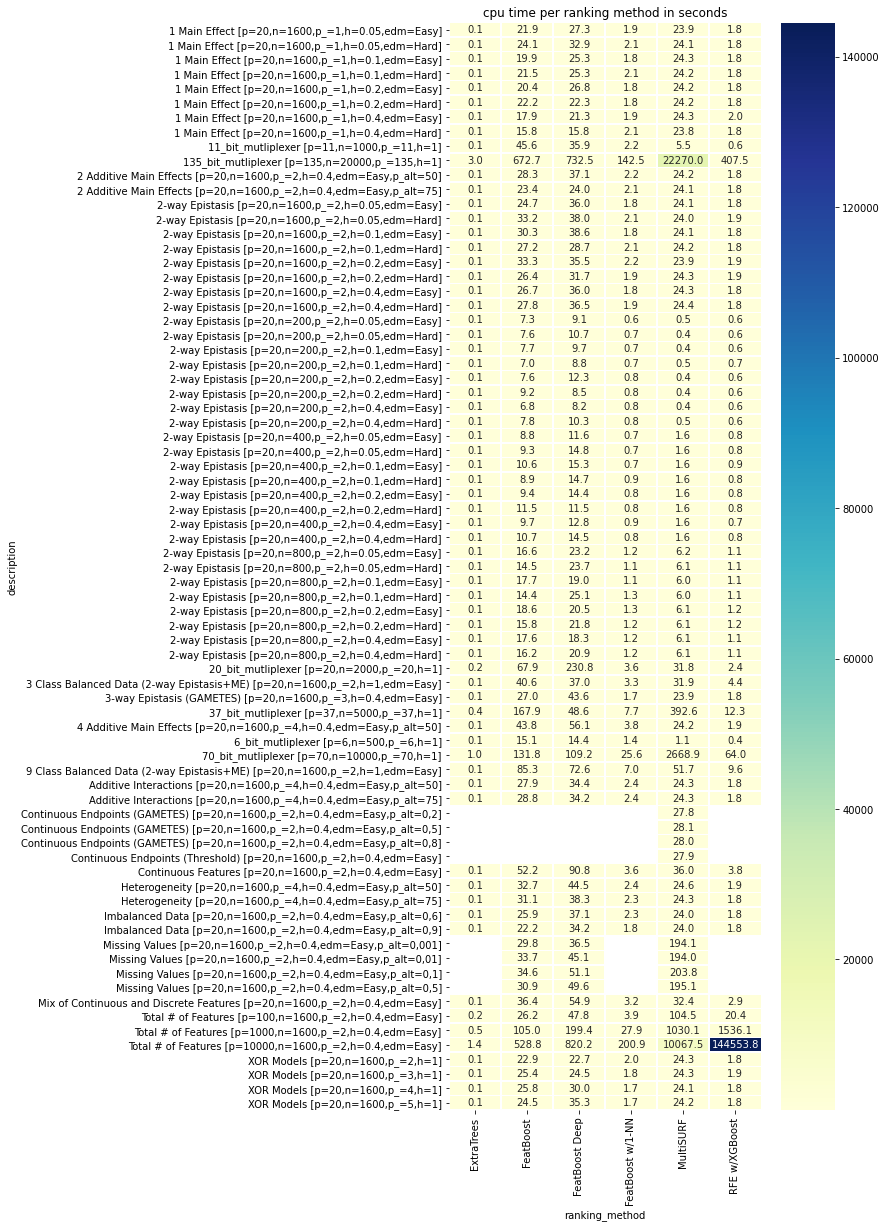

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt
pivot = pd.pivot_table(statdata,\
    values='cpu_time', index=['description'], columns=['ranking_method'])
f, ax = plt.subplots(figsize=(7, 20))
ax = sns.heatmap(pivot, annot=True, fmt=".1f", linewidths=.5, cmap="YlGnBu", yticklabels=True, ax=ax)
plt.title('cpu time per ranking method in seconds')

# Statistical integrity testing

In [311]:
avgdata = interpdata.groupby(['description', 'ranking_method']).agg('mean').reset_index()
avgdata.shape

(418, 8)

### ROC-AUC

In [164]:
from scipy.stats import friedmanchisquare
pivot_rocauc = pd.pivot_table(avgdata, values='roc_auc',\
    index=['description'], columns=['ranking_method'])
res = friedmanchisquare(*pivot_rocauc.values.transpose())
print('significant' if res.pvalue < 0.05 else 'insignificant')
res

significant


FriedmanchisquareResult(statistic=201.4500390320062, pvalue=1.390596061390306e-41)

In [160]:
melted_rocauc = avgdata.melt(id_vars=['description', 'ranking_method'], value_vars=['roc_auc'])
melted_rocauc.head()

,description,ranking_method,variable,value
0,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",ExtraTrees,roc_auc,0.965875
1,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",FeatBoost,roc_auc,0.941528
2,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",FeatBoost Deep,roc_auc,0.939343
3,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",FeatBoost w/1-NN,roc_auc,0.972448
4,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",MultiSURF,roc_auc,0.994949


In [158]:
import scikit_posthocs  as sp
pc = sp.posthoc_nemenyi_friedman(melted_rocauc, y_col='value', block_col='description',
    group_col='ranking_method', melted=True)
pc

,ExtraTrees,FeatBoost,FeatBoost Deep,FeatBoost w/1-NN,MultiSURF,RFE w/XGBoost
ExtraTrees,-1.00000,0.001000,0.001000,0.001000,0.031570,0.900000
FeatBoost,0.00100,-1.000000,0.883234,0.161496,0.001000,0.001000
FeatBoost Deep,0.00100,0.883234,-1.000000,0.006938,0.001000,0.001000
FeatBoost w/1-NN,0.00100,0.161496,0.006938,-1.000000,0.001000,0.001000
MultiSURF,0.03157,0.001000,0.001000,0.001000,-1.000000,0.353392
RFE w/XGBoost,0.90000,0.001000,0.001000,0.001000,0.353392,-1.000000


(<matplotlib.axes._subplots.AxesSubplot at 0x12bfc6978>,
 <matplotlib.colorbar.ColorbarBase at 0x12a9e6c88>)

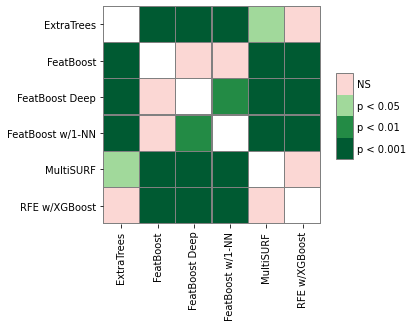

In [159]:
heatmap_args = {'linewidths': 0.25, 'linecolor': '0.5', 'clip_on': False, 'square': True, 'cbar_ax_bbox': [0.80, 0.35, 0.04, 0.3]}

### mAP

significant


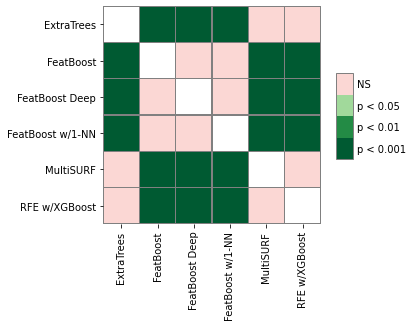

In [187]:
from scipy.stats import friedmanchisquare
import scikit_posthocs  as sp
pivot_rocauc = pd.pivot_table(avgdata, values='mAP',\
    index=['description'], columns=['ranking_method'])
res = friedmanchisquare(*pivot_rocauc.values.transpose())
if res.pvalue < 0.05:
    print('significant')
    melted_mAP = avgdata.melt(id_vars=['description', 'ranking_method'], value_vars=['mAP'])
    pc = sp.posthoc_nemenyi_friedman(melted_rocauc, y_col='value', block_col='description',
        group_col='ranking_method', melted=True)
    sp.sign_plot(pc, **heatmap_args)
    # plt.title('mAP significance levels')

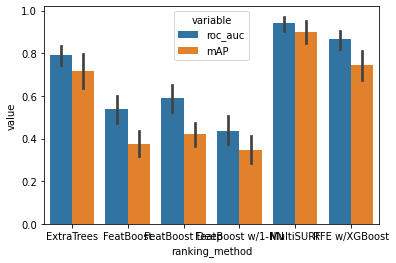

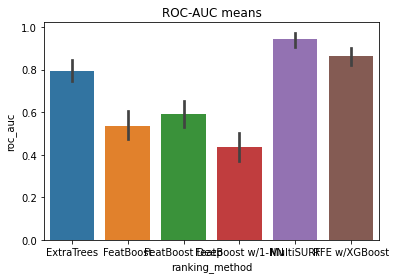

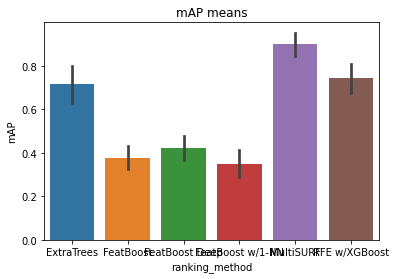

In [190]:
summary_ = avgdata.melt(id_vars=['ranking_method'], value_vars=['roc_auc', 'mAP'])
sns.barplot(data=summary_, x='ranking_method', y='value', hue='variable')
plt.show()
sns.barplot(data=avgdata, x='ranking_method', y='roc_auc')
plt.title('ROC-AUC means')
plt.show()
sns.barplot(data=avgdata, x='ranking_method', y='mAP')
plt.title('mAP means')
plt.show()